# MP05: Gillespie Direct SSA Engine Implementation
**Complex Systems / Physics 195**

**Objective.** Build a general-purpose Gillespie Direct SSA in Python from scratch, validate it against an analytical steady-state distribution, and analyze the impact of demographic noise on non-linear systems. Only the standard library (`random`, `math`), NumPy, SciPy (`scipy.stats`, pdf/cdf/χ² tails only) and Matplotlib are used; no SSA packages (Catalyst.jl, JumpProcesses.jl).

In [1]:
# pip install numpy scipy matplotlib       (run once if needed)
import math, os, random, sys
from typing import NamedTuple

import numpy as np
from scipy import stats            # used ONLY for pdf / cdf / χ² tail probabilities, never for the SSA itself
import matplotlib.pyplot as plt

plt.rcParams.update({"lines.linewidth": 2, "axes.grid": True, "grid.alpha": 0.25,
                     "legend.fontsize": 8, "axes.titlesize": 10, "axes.labelsize": 9})
os.makedirs("figures_pyth", exist_ok=True)      # figures are also saved here for the report

## KR1: Core Gillespie Direct Algorithm Implementation

### 1. Algorithm description & implementation

State $\mathbf{x}$, channels $\mu=1..M$ with propensities $a_\mu(\mathbf{x})$ and change vectors $\boldsymbol\nu_\mu$. Each step:

1. evaluate every $a_\mu(\mathbf{x})$ and the total $a_0=\sum_\mu a_\mu$;
2. sample the waiting time $\tau=-\ln(r_1)/a_0\sim\text{Exp}(a_0)$;
3. sample the channel $\mu$ by cumulative lookup: the smallest $\mu$ with $\sum_{\nu\le\mu}a_\nu > r_2a_0$, so $P(\mu)=a_\mu/a_0$;
4. advance $t\leftarrow t+\tau$, $\mathbf{x}\leftarrow\mathbf{x}+\boldsymbol\nu_\mu$.

In [2]:
# ------------------------------------------------------------------
# Model container: stoichiometry + in-place propensity function + parameters
# ------------------------------------------------------------------
class ReactionNetwork:
    def __init__(self, stoich, propensity, p, species=None, reactions=None):
        self.stoich = np.asarray(stoich, dtype=int)   # n_species x n_reactions; column μ is the change vector ν_μ
        self.propensity = propensity                  # propensity(a, x, p) fills a[μ] = a_μ(x) in place
        self.p = [float(v) for v in np.atleast_1d(p)] # parameters handed to the propensity function
        nspecies, nreact = self.stoich.shape
        self.species   = list(species)   if species   is not None else [f"X{i+1}" for i in range(nspecies)]
        self.reactions = list(reactions) if reactions is not None else [f"R{j+1}" for j in range(nreact)]
        # sparse change vectors (species index, ν) for fast state updates
        self._changes = [[(i, int(self.stoich[i, mu])) for i in range(nspecies) if self.stoich[i, mu] != 0]
                         for mu in range(nreact)]


# ------------------------------------------------------------------
# Channel selection by discrete cumulative-probability lookup
# Returns the smallest μ with  Σ_{ν≤μ} a_ν > r2 · a0.   (μ is a 0-based index here)
# ------------------------------------------------------------------
def sample_reaction(a, a0, r2):
    target = r2 * a0                   # uniform point on [0, a0)
    cum = 0.0
    for mu in range(len(a)):
        cum += a[mu]                   # running cumulative propensity
        if target < cum:               # strict '<': a channel with a_μ = 0 can never be chosen
            return mu
    # Floating-point round-off fallback: last channel with positive propensity
    for mu in range(len(a) - 1, -1, -1):
        if a[mu] > 0:
            return mu
    raise RuntimeError("sample_reaction called with all-zero propensities")


# ------------------------------------------------------------------
# Gillespie Direct Method
#   net        : ReactionNetwork
#   x0         : initial copy numbers
#   tmax       : end time (may be math.inf: run until absorption or max_events)
#   rng        : random.Random instance
#   record     : True  -> store the full trajectory (times, states)
#                False -> store only the final state (fast, used for large ensembles)
# Returns SSAResult(times, states, x_final, t_final, n_events); `states` is n_species x n_points.
# ------------------------------------------------------------------
class SSAResult(NamedTuple):
    times: np.ndarray
    states: np.ndarray
    x_final: np.ndarray
    t_final: float
    n_events: int


def gillespie_direct(net, x0, tmax, rng=None, record=True, max_events=None):
    if rng is None:
        rng = random.Random()
    if max_events is None:
        max_events = sys.maxsize
    changes = net._changes
    nspecies, nreact = net.stoich.shape
    propensity, p, rand = net.propensity, net.p, rng.random

    x = [int(v) for v in x0]           # working copy of the state
    a = [0.0] * nreact                 # propensities a_μ(x)
    t = 0.0
    nev = 0
    hit_tmax = False
    absorbed = False

    times, states = [], []
    if record:
        times.append(0.0); states.append(tuple(x))

    while nev < max_events:
        # (1) propensities a_μ(x) and their sum a0
        propensity(a, x, p)
        a0 = sum(a)

        # (2) ABSORBING STATE: a0 = 0 means no reaction can ever fire again -> stop
        if not (a0 > 0):
            absorbed = True
            break

        # (3) time to next event, τ ~ Exp(a0).  1 - U[0,1) lies in (0,1], so log() is finite.
        tau = -math.log(1.0 - rand()) / a0

        # (4) TIME-BOUNDARY OVERSHOOT: if the next event falls beyond tmax, discard it.
        #     (valid because the exponential is memoryless: the state is frozen on [t, tmax])
        if t + tau > tmax:
            hit_tmax = True
            break
        t += tau

        # (5) which reaction fires: μ chosen with probability a_μ / a0
        mu = sample_reaction(a, a0, rand())

        # (6) update the state with ν_μ
        for i, nu in changes[mu]:
            x[i] += nu
        nev += 1
        if record:
            times.append(t); states.append(tuple(x))

    # If the run ended by absorption or at tmax (finite), report t_final = tmax
    t_final = float(tmax) if (hit_tmax or (absorbed and math.isfinite(tmax))) else t
    if record and t_final > times[-1]:
        times.append(t_final); states.append(tuple(x))     # extend the final plateau for plotting
    M = np.array(states, dtype=int).T if record else np.zeros((nspecies, 0), dtype=int)
    return SSAResult(np.array(times), M, np.array(x, dtype=int), t_final, nev)


# Sample many recorded runs on a common time grid (paths are piecewise constant).
# `s` is the 0-based species index.
def ensemble_on_grid(runs, grid, s):
    grid = np.asarray(grid)
    out = np.empty((len(runs), len(grid)), dtype=int)
    for r, run in enumerate(runs):
        idx = np.searchsorted(run.times, grid, side="right") - 1      # last event time <= g
        out[r, :] = run.states[s, idx]
    return out

### 2. Implementation verification

**Absorbing states ($a_0=0$).** If every propensity is zero the waiting time $\tau=-\ln r/a_0$ would be infinite, so the solver tests `a0 > 0` before sampling and exits the loop. The state is then frozen. With finite `tmax` the plateau is extended to `tmax`; with `tmax = math.inf` the run ends at the last event. This is how an SIR trajectory terminates at $I=0$ (both $a_1\propto SI$ and $a_2\propto I$ vanish). The `not (a0 > 0)` form also stops on `NaN`.

**Time-boundary overshoot ($t+\tau>t_{\max}$).** The candidate event is discarded and the state is held at its current value up to `tmax`. This is exact, not an approximation: the exponential waiting time is memoryless, so no event occurred in $(t,t_{\max}]$ with the correct probability, and the state at `tmax` is the state after the last event before it. Discarding (rather than applying) the event avoids a bias toward states that lie beyond the observation window.

**Primitive tests.** (a) channel frequencies for propensities `[1,3,0,6]` against `[0.1,0.3,0,0.6]` (χ² test; the zero-rate channel must never fire); (b) inter-event times of a single constant-rate reaction against Exp(5) (mean, std, Kolmogorov-Smirnov).

In [3]:
def _run_primitive_tests():
    rng = random.Random(1)
    # ---- (a) channel selection ---------------------------------------------------
    a = [1.0, 3.0, 0.0, 6.0]; a0 = sum(a); n = 10**6
    counts = np.zeros(len(a), dtype=int)
    for _ in range(n):
        counts[sample_reaction(a, a0, rng.random())] += 1
    probs = np.array(a) / a0
    nz = np.where(probs > 0)[0]
    chi2 = np.sum((counts[nz] - n * probs[nz]) ** 2 / (n * probs[nz]))
    print("Channel frequencies  empirical:", np.round(counts / n, 4), "  exact:", probs)
    print(f"  zero-propensity channel picked {counts[2]} times;  χ² = {chi2:.2f}, p = {stats.chi2.sf(chi2, len(nz) - 1):.3f}")

    # ---- (b) waiting times through the full solver ---------------------------------
    rate = 5.0
    def const_prop(a, x, p):
        a[0] = p[0]
    poisson_proc = ReactionNetwork([[1]], const_prop, [rate])
    r = gillespie_direct(poisson_proc, [0], math.inf, rng=rng, max_events=200_000)
    taus = np.diff(r.times)
    print(f"Waiting times: mean = {taus.mean():.4f} (exact {1/rate:.4f}), std = {taus.std(ddof=1):.4f} (exact {1/rate:.4f})")
    srt = np.sort(taus); m = len(srt); F = stats.expon(scale=1 / rate).cdf(srt); i = np.arange(1, m + 1)
    D = np.max(np.maximum(np.abs(i / m - F), np.abs((i - 1) / m - F)))
    print(f"  KS distance = {D:.5f}  (5% critical value {1.36 / math.sqrt(m):.5f})")

    # ---- (c) absorbing state and overshoot ---------------------------------------
    def death_prop(a, x, p):
        a[0] = p[0] * x[0]
    dying = ReactionNetwork([[-1]], death_prop, [1.0])
    r1 = gillespie_direct(dying, [20], math.inf, rng=rng)
    print(f"Pure death, tmax = Inf : ended at X = {r1.x_final[0]} after {r1.n_events} events (absorbed)")
    r2 = gillespie_direct(dying, [20], 0.5, rng=rng)
    print(f"Pure death, tmax = 0.5 : t_final = {r2.t_final:.2f}, last recorded time = {r2.times[-1]:.2f} ≤ tmax")

_run_primitive_tests()

Channel frequencies  empirical: [0.0997 0.2997 0.     0.6006]   exact: [0.1 0.3 0.  0.6]
  zero-propensity channel picked 0 times;  χ² = 1.76, p = 0.414
Waiting times: mean = 0.1990 (exact 0.2000), std = 0.1992 (exact 0.2000)
  KS distance = 0.00259  (5% critical value 0.00304)
Pure death, tmax = Inf : ended at X = 0 after 20 events (absorbed)
Pure death, tmax = 0.5 : t_final = 0.50, last recorded time = 0.50 ≤ tmax


## KR2: Sanity check & model validation (constitutive birth-death)

### 1. Model formulation

$$\varnothing\xrightarrow{k_1}X\ \ (a_1=k_1),\qquad X\xrightarrow{k_2}\varnothing\ \ (a_2=k_2X)$$

Parameters: $k_1=50.0$, $k_2=1.0$, $x_0=[0]$, $t_{\max}=10.0$, so $\lambda=k_1/k_2=50$. The exact solution from $x_0=0$ is Poisson with mean $\lambda(1-e^{-k_2t})$ at every $t$; at $t_{\max}=10$ the transient correction is $\lambda e^{-10}\approx 2\times10^{-3}$, which is negligible.

In [4]:
k1, k2 = 50.0, 1.0
λ = k1 / k2

def bd_prop(a, x, p):                  # a1 = k1, a2 = k2·X
    a[0] = p[0]
    a[1] = p[1] * x[0]

bd = ReactionNetwork([[1, -1]], bd_prop, [k1, k2],
                     species=["X"], reactions=["∅ → X (birth)", "X → ∅ (death)"])

ntraj = 1000
tmax_bd = 10.0
tgrid_bd = np.linspace(0.0, tmax_bd, 101)          # 0.0:0.1:10.0
rng_bd = random.Random(20240601)

bd_runs = [gillespie_direct(bd, [0], tmax_bd, rng=rng_bd) for _ in range(ntraj)]
Xbd     = ensemble_on_grid(bd_runs, tgrid_bd, 0)   # ntraj x len(tgrid)
finals  = Xbd[:, -1]                               # X(t_max) for each run

### 2. Results & validation plot
Normalized histogram of $X(t_{\max})$ over 1,000 runs, overlaid with $P(X=k)=\lambda^ke^{-\lambda}/k!$, $\lambda=50$; and the transient mean and variance against theory.

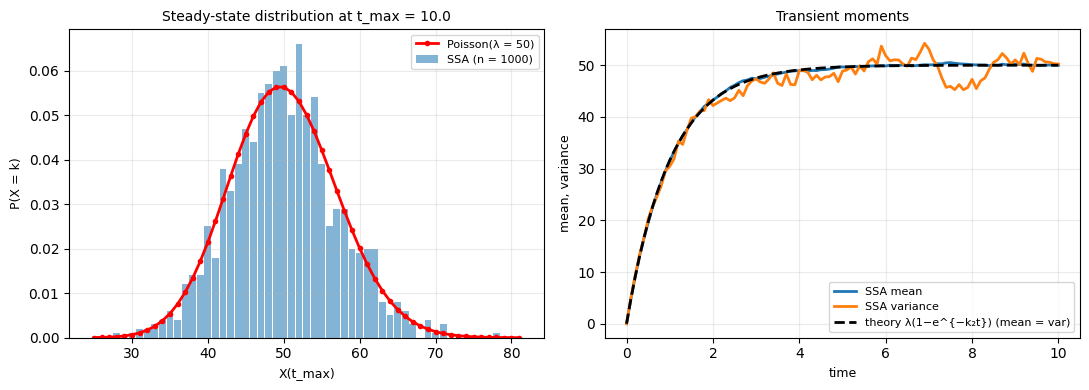

In [5]:
ks      = np.arange(max(0, finals.min() - 3), finals.max() + 4)
emp_pmf = np.array([(finals == m).sum() / ntraj for m in ks])

fig_kr2, (p1, p2) = plt.subplots(1, 2, figsize=(11, 4))
p1.bar(ks, emp_pmf, alpha=0.55, label=f"SSA (n = {ntraj})", width=0.9)
p1.plot(ks, stats.poisson.pmf(ks, λ), "o-", c="red", ms=3, label=f"Poisson(λ = {int(λ)})")
p1.set(xlabel="X(t_max)", ylabel="P(X = k)", title=f"Steady-state distribution at t_max = {tmax_bd}")
p1.legend()

tt = tgrid_bd
p2.plot(tt, Xbd.mean(axis=0), label="SSA mean")
p2.plot(tt, Xbd.var(axis=0, ddof=1), label="SSA variance")
p2.plot(tt, λ * (1 - np.exp(-k2 * tt)), "--", c="black", label="theory λ(1−e^{−k₂t}) (mean = var)")
p2.set(xlabel="time", ylabel="mean, variance", title="Transient moments")
p2.legend(loc="lower right")

fig_kr2.tight_layout()
fig_kr2.savefig("figures_pyth/kr2_birth_death.png", dpi=150)
plt.show()

### 3. Statistical comparison
The table below is printed in Markdown, ready to paste into the report. Because there are only 1,000 samples, a non-zero relative error is expected from sampling noise alone: $\text{SE}(\bar X)=\sqrt{\lambda/n}$ and $\text{SE}(s^2)\approx\sqrt{(\lambda+2\lambda^2)/n}$. These are printed next to the observed errors, along with a χ² goodness-of-fit test (tail bins pooled to expected count ≥ 5) and a replication study.

In [6]:
def relerr(e, t):
    return 100 * abs(e - t) / t

emp_mean = finals.mean();  emp_var = finals.var(ddof=1)
se_mean  = math.sqrt(λ / ntraj)
se_var   = math.sqrt((λ + 2 * λ**2) / ntraj)

print(f"| Metric | Empirical (SSA Ensemble) | Theoretical Poisson (λ = {int(λ)}) | Relative Error (%) |")
print("|---|---|---|---|")
print(f"| Mean ⟨X⟩ | {emp_mean:.3f} | {λ:.2f} | {relerr(emp_mean, λ):.3f} |")
print(f"| Variance σ²_X | {emp_var:.3f} | {λ:.2f} | {relerr(emp_var, λ):.3f} |")
print(f"\nExpected sampling noise (1 s.e.): mean {100 * se_mean / λ:.3f}%,  variance {100 * se_var / λ:.3f}%")
print(f"Observed deviation in s.e. units : mean {(emp_mean - λ) / se_mean:.2f},  variance {(emp_var - λ) / se_var:.2f}")
print(f"Fano factor = {emp_var / emp_mean:.3f} (Poisson ⇒ 1)")

| Metric | Empirical (SSA Ensemble) | Theoretical Poisson (λ = 50) | Relative Error (%) |
|---|---|---|---|
| Mean ⟨X⟩ | 50.000 | 50.00 | 0.000 |
| Variance σ²_X | 50.226 | 50.00 | 0.452 |

Expected sampling noise (1 s.e.): mean 0.447%,  variance 4.494%
Observed deviation in s.e. units : mean 0.00,  variance 0.10
Fano factor = 1.005 (Poisson ⇒ 1)


In [7]:
# Pearson χ² goodness-of-fit against Poisson(λ); tail bins pooled so every expected count >= minexp
class GOF(NamedTuple):
    chi2: float
    df: int
    p: float

def poisson_gof(samples, lam, minexp=5.0):
    samples = np.asarray(samples); n = len(samples); P = stats.poisson(lam)
    ms   = np.arange(0, 1001)
    kmin = int(ms[np.argmax(n * P.cdf(ms) >= minexp)])             # smallest m with n·P(X≤m) ≥ minexp
    kmax = int(ms[np.where(n * P.sf(ms - 1) >= minexp)[0][-1]])    # largest  m with n·P(X≥m) ≥ minexp
    obs  = [float((samples <= kmin).sum())]
    expd = [n * P.cdf(kmin)]
    for m in range(kmin + 1, kmax):
        obs.append(float((samples == m).sum())); expd.append(n * P.pmf(m))
    obs.append(float((samples >= kmax).sum())); expd.append(n * P.sf(kmax - 1))
    obs, expd = np.array(obs), np.array(expd)
    chi2 = float(np.sum((obs - expd) ** 2 / expd)); df = len(obs) - 1
    return GOF(chi2, df, float(stats.chi2.sf(chi2, df)))

gof = poisson_gof(finals, λ)
print(f"χ² GOF at t_max: χ² = {gof.chi2:.2f}, df = {gof.df}, p = {gof.p:.3f} → "
      f"{'cannot reject Poisson(λ)' if gof.p > 0.05 else 'REJECTED'} at the 5% level")

# Replication study: a correct sampler gives ~uniform p-values, so ≈5% of replicates reject at 5%
reps = 50
rng_rep = random.Random(777)
pvals = np.array([poisson_gof([gillespie_direct(bd, [0], tmax_bd, rng=rng_rep, record=False).x_final[0]
                               for _ in range(ntraj)], λ).p for _ in range(reps)])
print(f"Replicates: {reps} × {ntraj} runs.  Fraction rejecting at 5%: {np.mean(pvals < 0.05):.2f} "
      f"(≈ 0.05 expected);  mean p = {pvals.mean():.3f} (uniform ⇒ 0.5)")

χ² GOF at t_max: χ² = 31.12, df = 36, p = 0.700 → cannot reject Poisson(λ) at the 5% level
Replicates: 50 × 1000 runs.  Fraction rejecting at 5%: 0.04 (≈ 0.05 expected);  mean p = 0.509 (uniform ⇒ 0.5)


**Conclusion (KR2).** If the χ² p-value exceeds 0.05, the observed mean and variance lie within about 2 standard errors of $\lambda=50$ (Fano ≈ 1), and the replicate rejection rate is near 5 %, the distribution of $X(t_{\max})$ is statistically indistinguishable from Poisson(50). This validates both the exponential waiting-time sampler and the channel-selection rule.

## KR3: Stochastic SIR epidemic trajectory dynamics

### 1. Model configuration

1. Infection: $S+I\xrightarrow{\beta/N}2I$, $\boldsymbol\nu_1=[-1,1,0]^T$, propensity $a_1=\beta SI/N$
2. Recovery: $I\xrightarrow{\gamma}R$, $\boldsymbol\nu_2=[0,-1,1]^T$, propensity $a_2=\gamma I$

Parameters: $N=500$, $I_0=3$, $S_0=497$, $R_0=0$, $\beta=0.3$, $\gamma=0.1$ ($\mathcal{R}_0=3.0$), $t_{\max}=100$. Mean-field ODE: $\dot S=-\beta SI/N,\ \dot I=\beta SI/N-\gamma I,\ \dot R=\gamma I$ (hand-written RK4). Ensemble: 1,000 SSA runs.

In [8]:
N      = 500
I0     = 3
S0     = N - I0
β      = 0.3
γ      = 0.1
R0_sir = β / γ
tmax_sir = 100.0

def sir_prop(a, x, p):
    a[0] = p[0] * x[0] * x[1] / p[2]       # infection  a1 = β S I / N
    a[1] = p[1] * x[1]                     # recovery   a2 = γ I

sir = ReactionNetwork([[-1,  0],
                       [ 1, -1],
                       [ 0,  1]], sir_prop, [β, γ, N],
                      species=["S", "I", "R"], reactions=["infection", "recovery"])

# ---- deterministic mean-field (RK4) -----------------------------------------
def sir_ode(β, γ, N, S0, I0, tmax, dt=0.01):
    def f(u):
        inf = β * u[0] * u[1] / N
        return np.array([-inf, inf - γ * u[1], γ * u[1]])
    nsteps = int(round(tmax / dt))
    ts = np.linspace(0.0, tmax, nsteps + 1)
    U = np.zeros((3, nsteps + 1)); U[:, 0] = [S0, I0, 0]
    for n in range(nsteps):
        u  = U[:, n]
        k1 = f(u); k2 = f(u + dt / 2 * k1); k3 = f(u + dt / 2 * k2); k4 = f(u + dt * k3)
        U[:, n + 1] = u + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)
    return ts, U

dt_ode = 0.01
ts_ode, U_ode = sir_ode(β, γ, N, S0, I0, tmax_sir, dt=dt_ode)

# ---- stochastic ensemble ---------------------------------------------------------
nens     = 1000
rng_sir  = random.Random(42)
sir_runs = [gillespie_direct(sir, [S0, I0, 0], tmax_sir, rng=rng_sir) for _ in range(nens)]

grid_sir = np.linspace(0.0, tmax_sir, 401)          # 0.0:0.25:100.0
I_ens    = ensemble_on_grid(sir_runs, grid_sir, 1)
I_mean   = I_ens.mean(axis=0)

# Outbreak classification (same 10 % rule as KR4): total infected = N - S_final
major_frac = 0.10
total_inf  = np.array([N - r.x_final[0] for r in sir_runs])      # R_final + I_final
is_major   = total_inf >= major_frac * N
peak_I     = np.array([r.states[1].max() for r in sir_runs])
peak_time  = np.array([r.times[np.argmax(r.states[1])] for r in sir_runs])

### 2. Trajectory visualizations
Twenty individual realizations of $I(t)$ (fade-outs in grey), the ensemble average over 1,000 runs, and the mean-field ODE. Panels B–D support the analysis questions: time-aligned major outbreaks, the final-size distribution, and the distribution of peak times.

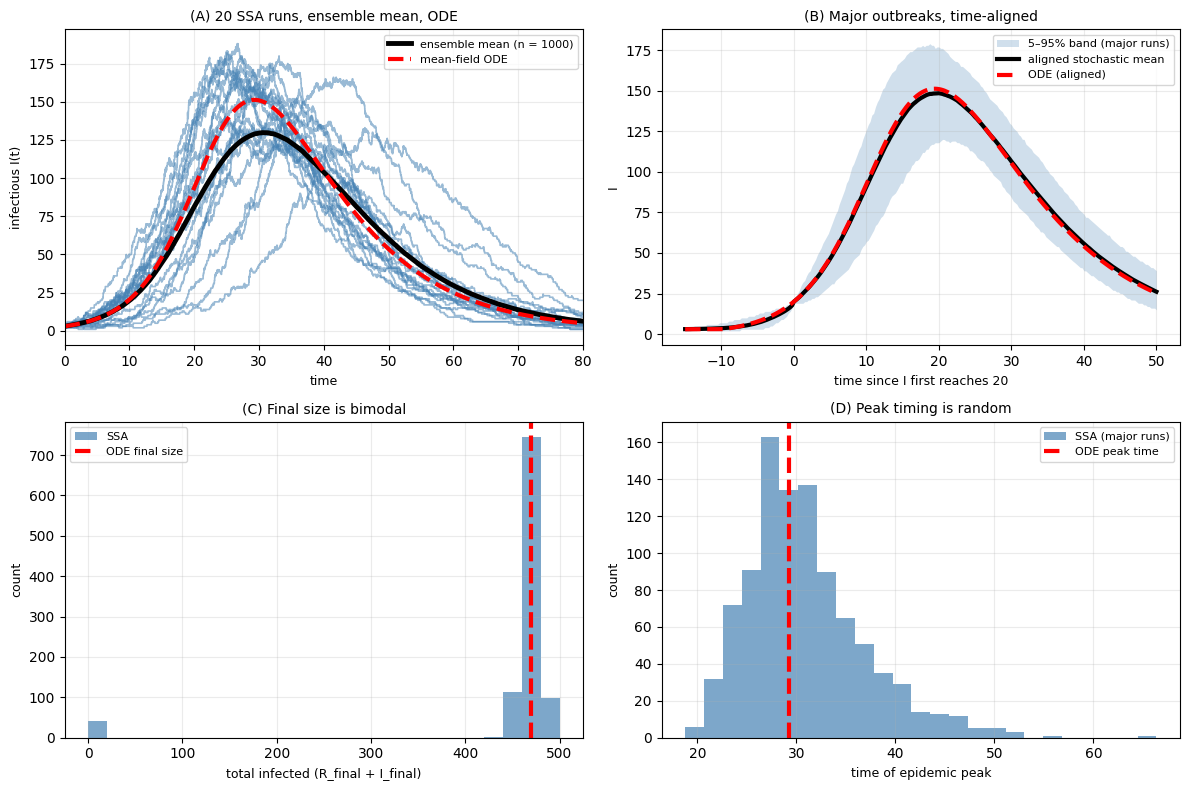

In [9]:
fig_kr3, axs = plt.subplots(2, 2, figsize=(12, 8))
pA, pB, pC, pD = axs.ravel()

# ---- (A) 20 single trajectories + ensemble mean + ODE ----------------------
for n, r in enumerate(sir_runs[:20]):
    pA.step(r.times, r.states[1], where="post", alpha=0.55, lw=1.2,
            c="steelblue" if is_major[n] else "gray")
pA.plot(grid_sir, I_mean, c="black", lw=3.5, label=f"ensemble mean (n = {nens})")
pA.plot(ts_ode, U_ode[1], c="red", ls="--", lw=3, label="mean-field ODE")
pA.set(xlabel="time", ylabel="infectious I(t)", xlim=(0, 80), title="(A) 20 SSA runs, ensemble mean, ODE")
pA.legend()

# ---- (B) major outbreaks aligned on first passage of I = thr ---------------------
thr = 20
def aligned_curves(runs, idxs, thr, τgrid):
    rows = []
    for i in idxs:
        r = runs[i]
        above = r.states[1] >= thr
        if not above.any():
            continue
        ta = r.times[np.argmax(above)]
        tq = np.maximum(ta + τgrid, 0.0)
        rows.append(r.states[1, np.searchsorted(r.times, tq, side="right") - 1])
    return np.array(rows, dtype=float)          # n_runs x len(τgrid)

τgrid  = np.linspace(-15.0, 50.0, 261)           # -15.0:0.25:50.0
A      = aligned_curves(sir_runs, np.where(is_major)[0], thr, τgrid)
A_mean = A.mean(axis=0)
A_lo   = np.quantile(A, 0.05, axis=0)
A_hi   = np.quantile(A, 0.95, axis=0)
ode_ta = ts_ode[np.argmax(U_ode[1] >= thr)]
ode_al = U_ode[1, np.clip(np.round((ode_ta + τgrid) / dt_ode).astype(int), 0, len(ts_ode) - 1)]

pB.fill_between(τgrid, A_lo, A_hi, color="steelblue", alpha=0.25, lw=0, label="5–95% band (major runs)")
pB.plot(τgrid, A_mean, c="black", lw=3, label="aligned stochastic mean")
pB.plot(τgrid, ode_al, c="red", ls="--", lw=3, label="ODE (aligned)")
pB.set(xlabel=f"time since I first reaches {thr}", ylabel="I", title="(B) Major outbreaks, time-aligned")
pB.legend()

# ---- (C) final size ---------------------------------------------------------------------
pC.hist(total_inf, bins=np.arange(0, N + 20, 20), color="steelblue", alpha=0.7, label="SSA")
pC.axvline(N - U_ode[0, -1], c="red", ls="--", lw=3, label="ODE final size")
pC.set(xlabel="total infected (R_final + I_final)", ylabel="count", title="(C) Final size is bimodal")
pC.legend()

# ---- (D) peak timing ---------------------------------------------------------------------
pD.hist(peak_time[is_major], bins=25, color="steelblue", alpha=0.7, label="SSA (major runs)")
pD.axvline(ts_ode[np.argmax(U_ode[1])], c="red", ls="--", lw=3, label="ODE peak time")
pD.set(xlabel="time of epidemic peak", ylabel="count", title="(D) Peak timing is random")
pD.legend()

fig_kr3.tight_layout()
fig_kr3.savefig("figures_pyth/kr3_sir.png", dpi=150)
plt.show()

In [10]:
mj = np.where(is_major)[0]
ode_peak = U_ode[1].max();  ode_pt = ts_ode[np.argmax(U_ode[1])];  ode_final = N - U_ode[0, -1]
dash = f"{'—':>10s}"

print(f"── SIR summary (N = {N}, ℛ₀ = {R0_sir:g}, I(0) = {I0}, {nens} runs) ──")
print(f"Early fade-out fraction: {1 - len(mj) / nens:.3f}   (branching theory (1/ℛ₀)^I₀ = {(1 / R0_sir)**I0:.3f})")
print(f"\n{'':<36s} {'SSA':>10s} {'ODE':>10s}")
print(f"{'peak I, mean over major runs':<36s} {peak_I[mj].mean():10.1f} {ode_peak:10.1f}")
print(f"{'peak I, std over major runs':<36s} {peak_I[mj].std(ddof=1):10.1f} {dash}")
print(f"{'peak of the ensemble-mean curve':<36s} {I_mean.max():10.1f} {ode_peak:10.1f}")
print(f"{'peak time, mean (major runs)':<36s} {peak_time[mj].mean():10.1f} {ode_pt:10.1f}")
print(f"{'peak time, std (major runs)':<36s} {peak_time[mj].std(ddof=1):10.1f} {dash}")
print(f"{'final size, mean (major runs)':<36s} {total_inf[mj].mean():10.1f} {ode_final:10.1f}")
print(f"{'final size, mean (all runs)':<36s} {total_inf.mean():10.1f} {ode_final:10.1f}")

idx_e = np.where(I_mean >= I_mean.max() / 2)[0]
fwhm_ens = (idx_e[-1] - idx_e[0]) * (grid_sir[1] - grid_sir[0])
idx_o = np.where(U_ode[1] >= ode_peak / 2)[0]
fwhm_ode = (idx_o[-1] - idx_o[0]) * dt_ode
print(f"\nFWHM of the ensemble-mean epidemic curve: {fwhm_ens:.1f}   vs   ODE: {fwhm_ode:.1f}")

── SIR summary (N = 500, ℛ₀ = 3, I(0) = 3, 1000 runs) ──
Early fade-out fraction: 0.041   (branching theory (1/ℛ₀)^I₀ = 0.037)

                                            SSA        ODE
peak I, mean over major runs              159.4      151.2
peak I, std over major runs                16.8          —
peak of the ensemble-mean curve           129.8      151.2
peak time, mean (major runs)               30.9       29.3
peak time, std (major runs)                 6.0          —
final size, mean (major runs)             469.8      470.2
final size, mean (all runs)               450.7      470.2

FWHM of the ensemble-mean epidemic curve: 30.8   vs   ODE: 26.9


### 3. Analysis questions

**1. Smearing of the epidemic peak.** The average of many runs is lower and wider than any single outbreak for three connected reasons.
- *Random start-up delay.* While $I$ is of order $I_0=3$, infections and recoveries are a few discrete random events, so the time to reach an appreciable prevalence varies between runs. The epidemic then grows as $e^{(\beta-\gamma)t}$, which amplifies this early randomness into a spread in peak times (panel D). Each run has a sharp peak of height ≈ the major-run mean, but at different times. Averaging across these time-shifted peaks gives a lower and broader mean curve. Aligning major outbreaks on a common prevalence (panel B) removes most of this effect and the stochastic mean then follows the ODE shape much more closely.
- *Mixture with fade-outs.* A fraction of runs go extinct early and contribute $I\approx0$ at all later times. This pulls the average down by a factor of roughly $(1-P_{\text{fade}})$ (see KR4).

The printed table shows both effects: the peak of the ensemble-mean curve is below the mean single-run peak, and its FWHM is larger than the ODE's.

**2. Absorbing boundary.** Both propensities contain a factor of $I$ ($a_1=\beta SI/N$, $a_2=\gamma I$), so at $I=0$ we get $a_0=0$ and no reaction can fire again, since infection needs an infectious individual and nothing reintroduces one. The solver detects $a_0=0$ and stops, so extinction is **final** and is reached in finite time at the moment the last infectious individual recovers. In contrast the ODE has $\dot I=I(\beta S/N-\gamma)$, so $I(t)=I_0\exp\!\big(\int(\beta S/N-\gamma)\,dt\big)>0$ for all finite $t$. $I$ decays exponentially toward 0 but never reaches it, and the ODE keeps an arbitrarily small residual infectious "density" indefinitely. Also, for $\mathcal{R}_0>1$ and $I_0>0$ the ODE cannot extinguish before the epidemic takes off, whereas the SSA can reach the absorbing boundary at small $I$ with non-zero probability.

## KR4: Early fade-out & stochastic extinction analysis

### 1. Empirical vs. theoretical extinction sweep

Sweep $I_0\in\{1,\dots,10\}$ with 1,000 runs per $I_0$ under $\mathcal{R}_0=1.5$ ($\beta=0.15$, $\gamma=0.1$, $N=500$). An **early fade-out** is a run in which $I(t)\to0$ before the total number infected, $R_{\text{final}}+I_{\text{final}}=N-S_{\text{final}}$, exceeds $10\%$ of $N$ (i.e. 50 individuals). Each run is simulated to absorption ($t_{\max}=\infty$) with `record=False`, then classified from the final state.

**Theory.** For small $I/N$, $I(t)$ is a linear birth-death branching process (birth rate $\beta$, death rate $\gamma$ per individual). The extinction probability from one case is $\gamma/\beta=1/\mathcal{R}_0$, so from $I_0$ independent lineages $P(\text{extinction})=(1/\mathcal{R}_0)^{I_0}$. As a secondary comparison we also plot a finite-$N$ refinement using $\mathcal{R}_0^{\text{eff}}=\mathcal{R}_0(N-I_0)/N$. Uncertainty is shown as Wilson 95 % intervals.

In [11]:
β4, γ4, N4 = 0.15, 0.1, 500
R0_4 = β4 / γ4
sir4 = ReactionNetwork([[-1,  0],
                        [ 1, -1],
                        [ 0,  1]], sir_prop, [β4, γ4, N4],
                       species=["S", "I", "R"], reactions=["infection", "recovery"])

I0_list   = list(range(1, 11))
nruns     = 1000
fade_frac = 0.10
rng_fade  = random.Random(2025)

# Early fade-out: extinction reached while (R_final + I_final) = N - S_final is still below 10 % of N
def count_fadeouts(net, N, I0, nruns, rng, frac=0.10):
    nminor = 0
    for _ in range(nruns):
        res = gillespie_direct(net, [N - I0, I0, 0], math.inf, rng=rng, record=False)   # run to absorption
        if (N - res.x_final[0]) < frac * N:
            nminor += 1
    return nminor

def wilson(kk, n, z=1.96):
    ph = kk / n; den = 1 + z**2 / n
    c = (ph + z**2 / (2 * n)) / den
    h = z * math.sqrt(ph * (1 - ph) / n + z**2 / (4 * n**2)) / den
    return (c - h, c + h)

nmin  = np.array([count_fadeouts(sir4, N4, i0, nruns, rng_fade, frac=fade_frac) for i0 in I0_list])
emp   = nmin / nruns
ci    = [wilson(kk, nruns) for kk in nmin]
lo    = np.array([c[0] for c in ci]);  hi = np.array([c[1] for c in ci])
q_th  = (1 / R0_4) ** np.array(I0_list)
q_ref = np.array([min(1.0, 1 / (R0_4 * (N4 - i0) / N4)) ** i0 for i0 in I0_list])

print(f"{'I0':>4s} {'minor':>7s} {'empirical':>10s} {'Wilson 95% CI':>19s} {'theory':>10s} {'refined':>10s} {'z':>7s} {'in CI?':>8s}")
for m, i0 in enumerate(I0_list):
    z = (emp[m] - q_th[m]) / math.sqrt(q_th[m] * (1 - q_th[m]) / nruns)
    ci_txt = f"[{lo[m]:7.4f}, {hi[m]:7.4f}]"
    print(f"{i0:4d} {nmin[m]:7d} {emp[m]:10.4f}  {ci_txt} {q_th[m]:10.4f} {q_ref[m]:10.4f} {z:7.2f} "
          f"{'yes' if lo[m] <= q_th[m] <= hi[m] else 'no':>8s}")

  I0   minor  empirical       Wilson 95% CI     theory    refined       z   in CI?
   1     649     0.6490  [ 0.6189,  0.6780]     0.6667     0.6680   -1.19      yes
   2     452     0.4520  [ 0.4214,  0.4830]     0.4444     0.4480    0.48      yes
   3     323     0.3230  [ 0.2947,  0.3526]     0.2963     0.3017    1.85      yes
   4     226     0.2260  [ 0.2012,  0.2529]     0.1975     0.2040    2.26       no
   5     156     0.1560  [ 0.1348,  0.1798]     0.1317     0.1385    2.27       no
   6      91     0.0910  [ 0.0747,  0.1104]     0.0878     0.0944    0.36      yes
   7      71     0.0710  [ 0.0567,  0.0886]     0.0585     0.0646    1.68      yes
   8      44     0.0440  [ 0.0329,  0.0586]     0.0390     0.0444    0.81      yes
   9      31     0.0310  [ 0.0219,  0.0437]     0.0260     0.0306    0.99      yes
  10      28     0.0280  [ 0.0194,  0.0402]     0.0173     0.0212    2.58       no


### 2. Outbreak probability plot
Empirical early fade-out fraction (points with 95 % Wilson intervals) against $(1/\mathcal{R}_0)^{I_0}$. The top panel uses a linear $y$-axis and the bottom a log axis, where geometric decay is a straight line.

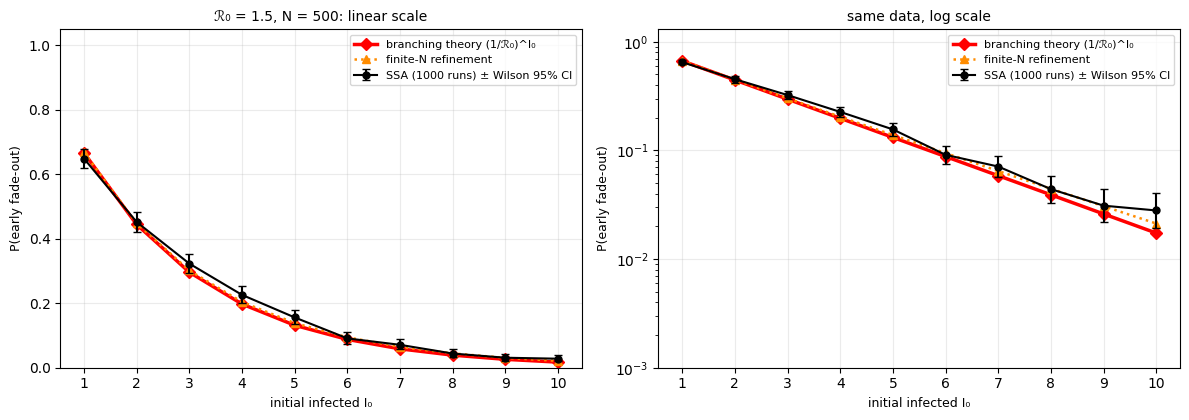

In [12]:
floor_y = 1e-3
def sweep_plot(ax, logy=False):
    fl = floor_y if logy else 0.0
    ax.plot(I0_list, np.maximum(q_th, fl), "-D", c="red", lw=2.5, label="branching theory (1/ℛ₀)^I₀")
    ax.plot(I0_list, np.maximum(q_ref, fl), ":^", c="darkorange", lw=1.8, label="finite-N refinement")
    e = np.maximum(emp, fl)
    ax.errorbar(I0_list, e, yerr=[np.maximum(e - lo, 0), np.maximum(hi - e, 0)], fmt="-o", c="black", lw=1.5,
                ms=5, capsize=3, label=f"SSA ({nruns} runs) ± Wilson 95% CI")
    ax.set(xlabel="initial infected I₀", ylabel="P(early fade-out)", xticks=I0_list)
    if logy:
        ax.set_yscale("log"); ax.set_ylim(floor_y, 1.3)
    else:
        ax.set_ylim(0, 1.05)
    ax.legend(loc="upper right")

fig_kr4, (pK1, pK2) = plt.subplots(1, 2, figsize=(12, 4.3))
sweep_plot(pK1, logy=False); pK1.set_title(f"ℛ₀ = {R0_4:g}, N = {N4}: linear scale")
sweep_plot(pK2, logy=True);  pK2.set_title("same data, log scale")
fig_kr4.tight_layout()
fig_kr4.savefig("figures_pyth/kr4_fadeout.png", dpi=150)
plt.show()

### 3. Discussion: why mean-field models miss early fade-out when $\mathcal{R}_0>1$

* **Deterministic dynamics have no extinction mechanism at small counts.** The ODE $\dot I=I(\beta S/N-\gamma)$ evolves a continuous *density*. At $t=0$ with $S\approx N$ it gives $\dot I/I=\beta-\gamma>0$, so any $I_0>0$ grows. The model says that $I_0=1$ always produces a full epidemic. It treats $1$ individual as a quantity that can be rescaled, whereas a real individual is either infectious or has recovered.
* **Demographic noise is large exactly when it matters.** The relative fluctuation of a count is $\sim1/\sqrt{I}$. At $I\sim1$–10 the random order of "infect" vs "recover" events decides the outcome. A single early recovery before the first transmission ends the outbreak. The probability that the first event is a recovery is $\gamma/(\beta+\gamma)=0.4$ for $\mathcal{R}_0=1.5$, and the full branching analysis gives $1/\mathcal{R}_0\approx0.67$ for $I_0=1$.
* **The ODE is a statement about the mean of many large populations, not about one small one.** It is accurate only as $N,I_0\to\infty$ with $I_0/N$ fixed, where extinction probability $(1/\mathcal{R}_0)^{I_0}\to0$. This is why the sweep shows extinction probability dropping geometrically with $I_0$: the ODE is the limit in which this probability vanishes.
* **The absorbing boundary.** $I=0$ is absorbing in the SSA and reachable in finite time. It is only an asymptotic fixed point of the ODE, so the mean-field model has no way to reproduce a bimodal outcome ("outbreak or nothing").
* **Observed agreement.** The empirical fractions in the table above can be compared with $(1/\mathcal{R}_0)^{I_0}$ via the Wilson intervals and z-scores. Remaining differences are expected from (i) finite $N=500$ (susceptible depletion lowers the effective $\mathcal{R}_0$, which the refined curve captures), (ii) the 10 % classification threshold rather than a true early-time criterion, and (iii) Monte Carlo error. With 1,000 runs, large-$I_0$ points rest on only about 20 or fewer fade-out events.